# Hospital Data Analysis

LEGACY: This was the combined-source analysis notebook. Use hospital_analysis_csv.ipynb, hospital_analysis_excel.ipynb, or hospital_analysis_sql.ipynb for the separate source-specific versions.

In [30]:
## 1. Import Required Libraries

from datetime import datetime
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Make plots inline when run in Jupyter
%matplotlib inline


In [31]:
# 2. Select and Load a Data Source

import sqlite3
from contextlib import closing

# Choose 'csv', 'excel', or 'sql'.
DATA_SOURCE = 'csv'
def find_project_dir(start):
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'raw' / 'hospital_original.csv').is_file():
            return candidate
    raise FileNotFoundError('Could not find the project data directory.')

PROJECT_DIR = find_project_dir(Path.cwd().resolve())
CSV_PATH = PROJECT_DIR / 'data/raw/hospital_original.csv'
EXCEL_PATH = PROJECT_DIR / 'data/raw/hospital_original.xlsx'
EXCEL_SHEET_NAME = 0
SQLITE_DB_PATH = PROJECT_DIR / 'data/hospital.db'
SQL_TABLE_NAME = 'hospital'
# Optional: set a read-only SQLite SELECT query instead of a table name.
SQL_QUERY = None

required_columns = {
    'Patient_ID', 'Age', 'Gender', 'Condition',
    'Admission_Date', 'Discharge_Date', 'Patient_State',
    'Year_of_Admission', 'Length_of_Stay', 'Readmission',
    'Outcome', 'Satisfaction', 'Insurance_Claimed', 'Total_Cost'
}

if DATA_SOURCE == 'csv':
    if not CSV_PATH.exists():
        raise FileNotFoundError(f'CSV source not found: {CSV_PATH}')
    df = pd.read_csv(CSV_PATH)
elif DATA_SOURCE == 'excel':
    if not EXCEL_PATH.exists():
        raise FileNotFoundError(f'Excel source not found: {EXCEL_PATH}')
    df = pd.read_excel(EXCEL_PATH, sheet_name=EXCEL_SHEET_NAME)
elif DATA_SOURCE == 'sql':
    if not SQLITE_DB_PATH.exists():
        raise FileNotFoundError(f'SQLite database not found: {SQLITE_DB_PATH}')
    if SQL_QUERY is None:
        quoted_table = '"' + SQL_TABLE_NAME.replace('"', '""') + '"'
        query = f'SELECT * FROM {quoted_table}'
    else:
        query = SQL_QUERY

    # Open the database read-only so analysis cannot modify the source.
    database_uri = f'{SQLITE_DB_PATH.resolve().as_uri()}?mode=ro'
    with closing(sqlite3.connect(database_uri, uri=True)) as connection:
        df = pd.read_sql_query(query, connection)
else:
    raise ValueError("DATA_SOURCE must be one of: 'csv', 'excel', or 'sql'.")

df.columns = df.columns.astype(str).str.strip()
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

if df['Patient_ID'].duplicated().any():
    print('Warning: duplicate Patient_ID values found.')
if (pd.to_numeric(df['Age'], errors='coerce') < 0).any():
    print('Warning: invalid age values found.')
if (pd.to_numeric(df['Total_Cost'], errors='coerce') < 0).any():
    print('Warning: negative cost values found.')

print(f'Loaded {len(df)} rows from {DATA_SOURCE.upper()} source.')
df.head(11)


Loaded rows: 984


,Patient_ID,Age,Gender,Condition,Medication,Admission_Date,Discharge_Date,Patient_State,Year_of_Admission,Length_of_Stay,Readmission,Outcome,Satisfaction,Insurance_Claimed,Total_Cost
0,1,45,Female,Heart Disease,NaN,07-02-2024,12-02-2024,Kerala,2024,5,No,Recovered,4,Yes,15000
1,2,60,Male,Diabetes,NaN,11-03-2023,14-03-2023,Goa,2023,3,Yes,Stable,3,No,2000
2,3,32,Female,Fractured Arm,NaN,02-01-2025,03-01-2025,Maharastra,2025,1,No,Recovered,5,Yes,500
3,4,75,Male,Stroke,NaN,30-12-2023,06-01-2024,Manipur,2023,7,Yes,Stable,2,No,10000
4,5,50,Female,Cancer,NaN,10-05-2022,20-05-2022,Mizoram,2022,10,No,Recovered,4,No,25000
5,6,68,Male,Hypertension,NaN,27-06-2025,29-06-2025,Sikkim,2025,2,No,Stable,4,Yes,1000
6,7,55,Female,Appendicitis,NaN,13-12-2023,17-12-2023,Karnataka,2023,4,No,Recovered,3,No,8000
7,8,40,Male,Fractured Leg,NaN,28-07-2022,03-08-2022,Gujarat,2022,6,No,Recovered,4,Yes,3000
8,9,70,Female,Heart Attack,NaN,11-05-2023,19-05-2023,Kerala,2023,8,Yes,Stable,2,No,18000
9,10,25,Male,Allergic Reaction,NaN,25-04-2023,26-04-2023,Kerala,2023,1,No,Recovered,5,No,100


In [32]:
## 3. Clean, Validate, and Save Separate Copies

# Strip column names
df.columns = [c.strip() for c in df.columns]

# Fix types for numeric columns
for col in ['Age','Length_of_Stay','Satisfaction','Total_Cost']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Standardize yes/no fields
for col in ['Readmission','Insurance_Claimed']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.capitalize()
        df[col] = df[col].replace({'Yes':'Yes','No':'No','Nan':'No'})

for col in ['Gender', 'Condition', 'Patient_State', 'Outcome']:
    if col in df.columns:
        df[col] = df[col].astype('string').str.strip()

if 'Medication' in df.columns and df['Medication'].isna().all():
    print('Note: Medication is entirely missing and is excluded from the analysis.')

# Parse dates
for col in ['Admission_Date','Discharge_Date']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')

# Flag rows with an impossible admission/discharge order
invalid_stay = df['Discharge_Date'] < df['Admission_Date']
if invalid_stay.any():
    print(f'Warning: {invalid_stay.sum()} row(s) have discharge before admission.')

# Save the cleaned data without overwriting the read-only raw source
cleaned_path = PROJECT_DIR / 'data' / 'cleaned' / 'hospital_cleaned.csv'
cleaned_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(cleaned_path, index=False)

date_tag = datetime.now().strftime('%Y-%m-%d_%H%M%S')
versioned_path = PROJECT_DIR / 'data' / 'backups' / f'hospital_cleaned_{date_tag}.csv'
versioned_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(versioned_path, index=False)
print(f'Cleaned dataset saved to: {cleaned_path}')
print(f'Versioned backup saved to: {versioned_path}')

# Show cleaning results
print('Missing values per column:')
print(df.isna().sum())

df.head(10)


Cleaned dataset saved to: data\cleaned\hospital_cleaned.csv
Versioned backup saved to: data\backups\hospital_cleaned_2026-10-04.csv
Missing values per column:
Patient_ID             0
Age                    0
Gender                 0
Condition              0
Medication           984
Admission_Date         0
Discharge_Date         0
Patient_State          0
Year_of_Admission      0
Length_of_Stay         0
Readmission            0
Outcome                0
Satisfaction           0
Insurance_Claimed      0
Total_Cost             0
dtype: int64


,Patient_ID,Age,Gender,Condition,Medication,Admission_Date,Discharge_Date,Patient_State,Year_of_Admission,Length_of_Stay,Readmission,Outcome,Satisfaction,Insurance_Claimed,Total_Cost
0,1,45,Female,Heart Disease,NaN,2024-02-07,2024-02-12,Kerala,2024,5,No,Recovered,4,Yes,15000
1,2,60,Male,Diabetes,NaN,2023-03-11,2023-03-14,Goa,2023,3,Yes,Stable,3,No,2000
2,3,32,Female,Fractured Arm,NaN,2025-01-02,2025-01-03,Maharastra,2025,1,No,Recovered,5,Yes,500
3,4,75,Male,Stroke,NaN,2023-12-30,2024-01-06,Manipur,2023,7,Yes,Stable,2,No,10000
4,5,50,Female,Cancer,NaN,2022-05-10,2022-05-20,Mizoram,2022,10,No,Recovered,4,No,25000
5,6,68,Male,Hypertension,NaN,2025-06-27,2025-06-29,Sikkim,2025,2,No,Stable,4,Yes,1000
6,7,55,Female,Appendicitis,NaN,2023-12-13,2023-12-17,Karnataka,2023,4,No,Recovered,3,No,8000
7,8,40,Male,Fractured Leg,NaN,2022-07-28,2022-08-03,Gujarat,2022,6,No,Recovered,4,Yes,3000
8,9,70,Female,Heart Attack,NaN,2023-05-11,2023-05-19,Kerala,2023,8,Yes,Stable,2,No,18000
9,10,25,Male,Allergic Reaction,NaN,2023-04-25,2023-04-26,Kerala,2023,1,No,Recovered,5,No,100


In [33]:
## 4. Show Basic Dataset Information

print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)

# Show first 10 rows
df.head(10)


Shape: (984, 15)

Data types:
Patient_ID                    int64
Age                           int64
Gender                       object
Condition                    object
Medication                  float64
Admission_Date       datetime64[ns]
Discharge_Date       datetime64[ns]
Patient_State                object
Year_of_Admission             int64
Length_of_Stay                int64
Readmission                  object
Outcome                      object
Satisfaction                  int64
Insurance_Claimed            object
Total_Cost                    int64
dtype: object


,Patient_ID,Age,Gender,Condition,Medication,Admission_Date,Discharge_Date,Patient_State,Year_of_Admission,Length_of_Stay,Readmission,Outcome,Satisfaction,Insurance_Claimed,Total_Cost
0,1,45,Female,Heart Disease,NaN,2024-02-07,2024-02-12,Kerala,2024,5,No,Recovered,4,Yes,15000
1,2,60,Male,Diabetes,NaN,2023-03-11,2023-03-14,Goa,2023,3,Yes,Stable,3,No,2000
2,3,32,Female,Fractured Arm,NaN,2025-01-02,2025-01-03,Maharastra,2025,1,No,Recovered,5,Yes,500
3,4,75,Male,Stroke,NaN,2023-12-30,2024-01-06,Manipur,2023,7,Yes,Stable,2,No,10000
4,5,50,Female,Cancer,NaN,2022-05-10,2022-05-20,Mizoram,2022,10,No,Recovered,4,No,25000
5,6,68,Male,Hypertension,NaN,2025-06-27,2025-06-29,Sikkim,2025,2,No,Stable,4,Yes,1000
6,7,55,Female,Appendicitis,NaN,2023-12-13,2023-12-17,Karnataka,2023,4,No,Recovered,3,No,8000
7,8,40,Male,Fractured Leg,NaN,2022-07-28,2022-08-03,Gujarat,2022,6,No,Recovered,4,Yes,3000
8,9,70,Female,Heart Attack,NaN,2023-05-11,2023-05-19,Kerala,2023,8,Yes,Stable,2,No,18000
9,10,25,Male,Allergic Reaction,NaN,2023-04-25,2023-04-26,Kerala,2023,1,No,Recovered,5,No,100


In [34]:
## 5. Simple Analysis

# Financial: overall and by condition
if 'Total_Cost' in df.columns:
    total_cost_summary = df['Total_Cost'].describe()
    print('Total cost summary:\n', total_cost_summary)

    cost_by_condition = df.groupby('Condition')['Total_Cost'].mean().sort_values(ascending=False).head(10)
    print('\nTop 10 conditions by average cost:\n', cost_by_condition)

# Demographic: age and gender distributions
if 'Age' in df.columns:
    print('\nAge summary:\n', df['Age'].describe())

if 'Gender' in df.columns:
    gender_counts = df['Gender'].value_counts()
    print('\nGender counts:\n', gender_counts)

# Length of stay summary
if 'Length_of_Stay' in df.columns:
    print('\nLength of stay summary:\n', df['Length_of_Stay'].describe())
    los_by_condition = df.groupby('Condition')['Length_of_Stay'].mean().sort_values(ascending=False).head(10)
    print('\nTop 10 conditions by average length of stay:\n', los_by_condition)


Total cost summary:
 count      984.000000
mean      8367.479675
std       7761.990976
min        100.000000
25%       1000.000000
50%       6000.000000
75%      15000.000000
max      25000.000000
Name: Total_Cost, dtype: float64

Top 10 conditions by average cost:
 Condition
Cancer             25000.0
Prostate Cancer    20000.0
Heart Attack       18000.0
Heart Disease      15000.0
Childbirth         12000.0
Stroke             10000.0
Appendicitis        8000.0
Kidney Stones       6000.0
Osteoarthritis      4000.0
Fractured Leg       3000.0
Name: Total_Cost, dtype: float64

Age summary:
 count    984.000000
mean      53.754065
std       14.941135
min       25.000000
25%       45.000000
50%       55.000000
75%       65.000000
max       78.000000
Name: Age, dtype: float64

Gender counts:
 Gender
Female    524
Male      460
Name: count, dtype: int64

Length of stay summary:
 count    984.000000
mean      37.663618
std       19.595805
min        1.000000
25%       21.000000
50%       38.00

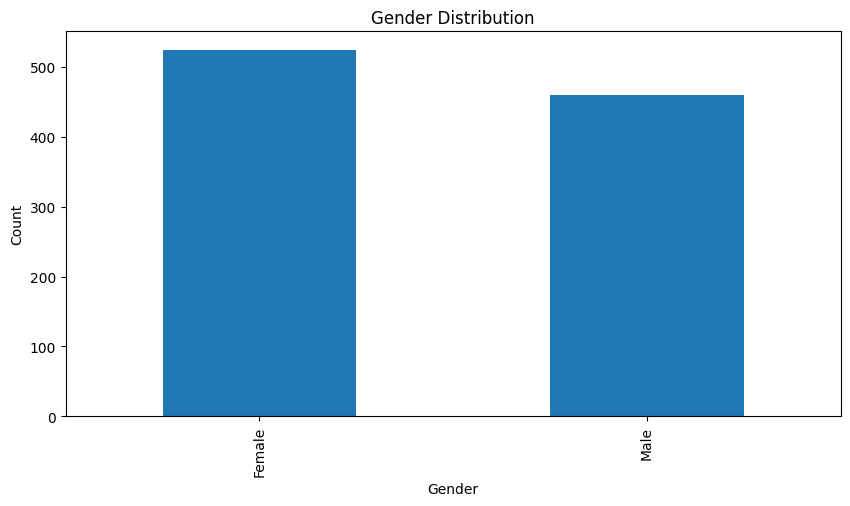

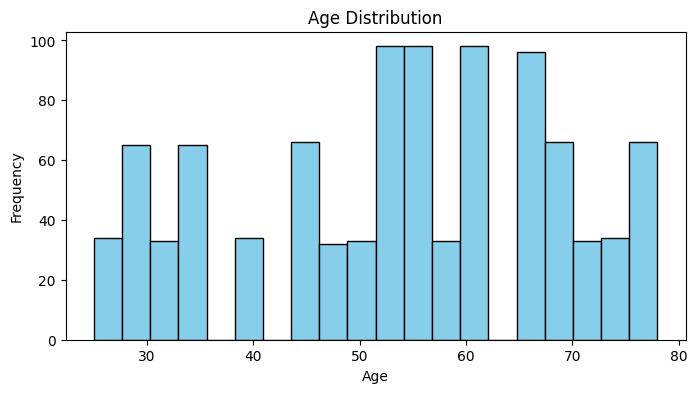

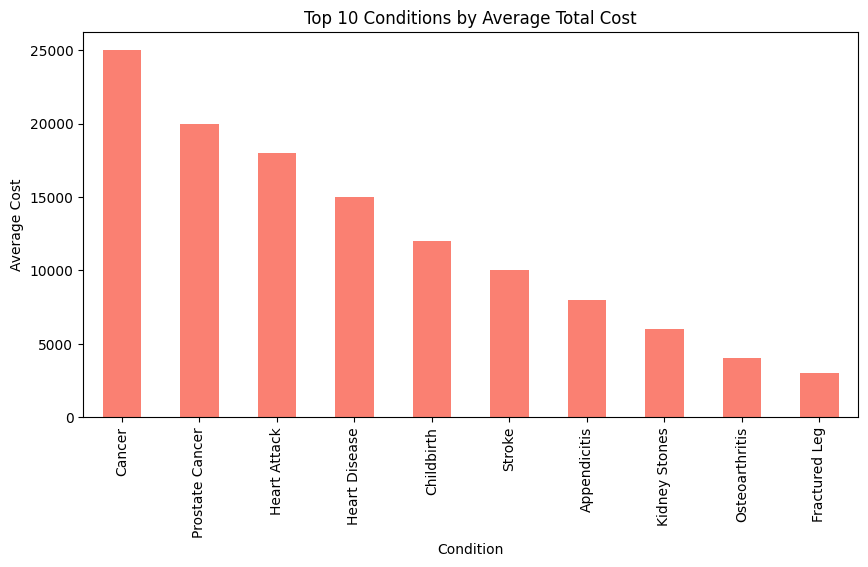

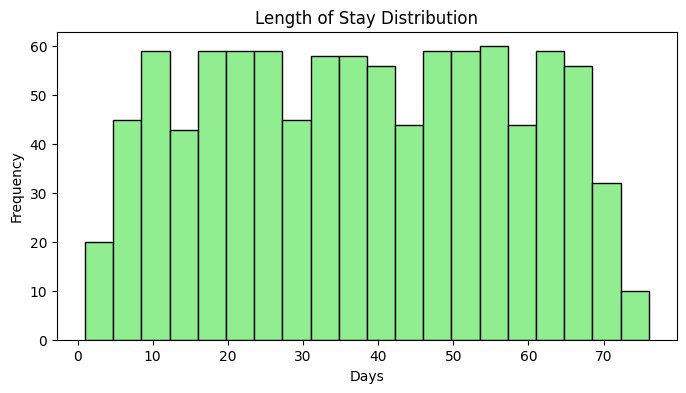

In [35]:
## 6. Visualize Analysis Summary with Matplotlib

plt.figure(figsize=(10,5))
# Gender distribution
if 'Gender' in df.columns:
    gender_counts.plot(kind='bar')
    plt.title('Gender Distribution')
    plt.xlabel('Gender')
    plt.ylabel('Count')
    plt.show()

# Age histogram
if 'Age' in df.columns:
    plt.figure(figsize=(8,4))
    plt.hist(df['Age'].dropna(), bins=20, color='skyblue', edgecolor='black')
    plt.title('Age Distribution')
    plt.xlabel('Age')
    plt.ylabel('Frequency')
    plt.show()

# Total cost by top conditions
if not cost_by_condition.empty:
    plt.figure(figsize=(10,5))
    cost_by_condition.plot(kind='bar', color='salmon')
    plt.title('Top 10 Conditions by Average Total Cost')
    plt.ylabel('Average Cost')
    plt.show()

# Length of stay histogram
if 'Length_of_Stay' in df.columns:
    plt.figure(figsize=(8,4))
    plt.hist(df['Length_of_Stay'].dropna(), bins=20, color='lightgreen', edgecolor='black')
    plt.title('Length of Stay Distribution')
    plt.xlabel('Days')
    plt.ylabel('Frequency')
    plt.show()


Total rows: 984
Average cost: 8367.48
Average length of stay: 37.66
Readmission rate: 26.83 %

Top 10 conditions by average cost:

Condition
Cancer             25000.0
Prostate Cancer    20000.0
Heart Attack       18000.0
Heart Disease      15000.0
Childbirth         12000.0
Stroke             10000.0
Appendicitis        8000.0
Kidney Stones       6000.0
Osteoarthritis      4000.0
Fractured Leg       3000.0
Name: Total_Cost, dtype: float64


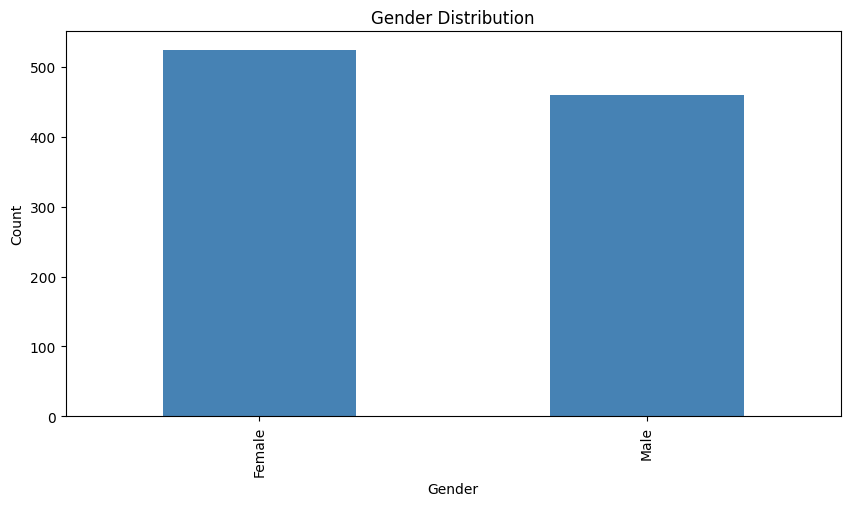

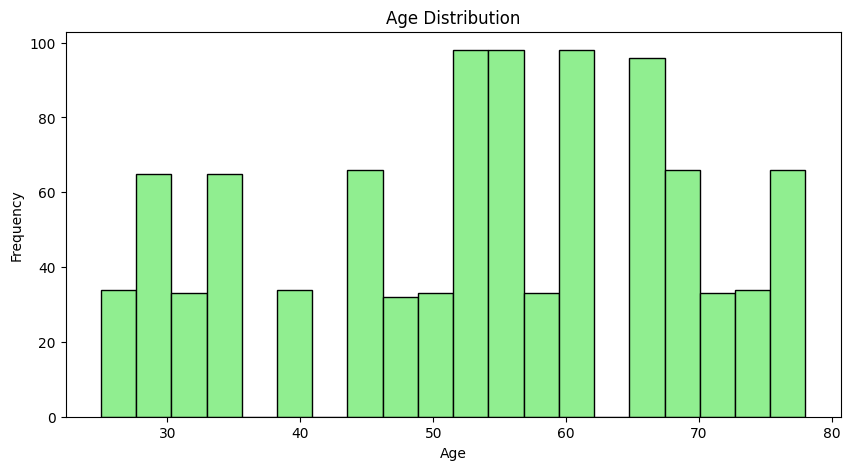

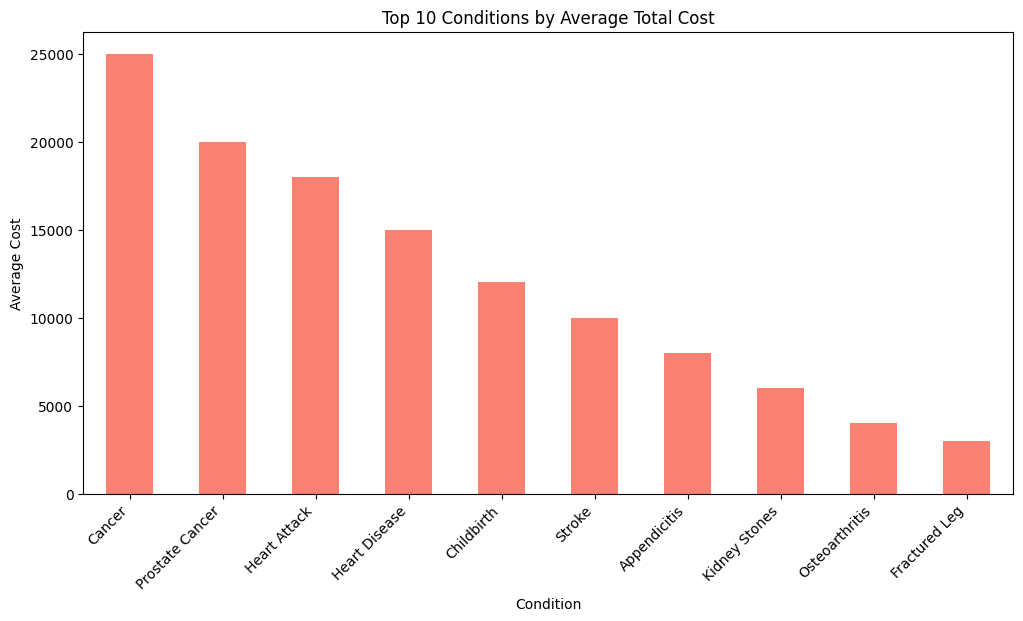

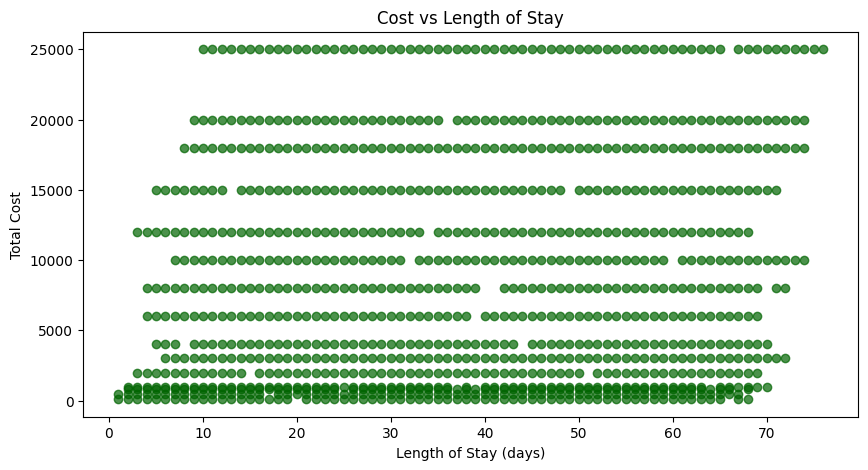

In [36]:

# Additional summary and cost-versus-stay visualization using the selected source.

print('Total rows:', len(df))
print('Average cost:', round(df['Total_Cost'].mean(), 2))
print('Average length of stay:', round(df['Length_of_Stay'].mean(), 2))
print('Readmission rate:', round(df['Readmission'].eq('Yes').mean() * 100, 2), '%')

print('''
Top 10 conditions by average cost:
''')
print(df.groupby('Condition')['Total_Cost'].mean().sort_values(ascending=False).head(10))

plt.figure(figsize=(10,5))
df['Gender'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Gender Distribution')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(10,5))
df['Age'].plot(kind='hist', bins=20, color='lightgreen', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(12,6))
df.groupby('Condition')['Total_Cost'].mean().sort_values(ascending=False).head(10).plot(kind='bar', color='salmon')
plt.title('Top 10 Conditions by Average Total Cost')
plt.ylabel('Average Cost')
plt.xticks(rotation=45, ha='right')
plt.show()

plt.figure(figsize=(10,5))
plt.scatter(df['Length_of_Stay'], df['Total_Cost'], alpha=0.7, color='darkgreen')
plt.title('Cost vs Length of Stay')
plt.xlabel('Length of Stay (days)')
plt.ylabel('Total Cost')
plt.show()
